In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs

# Generate sample customer data
X, y_true = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.2,
    random_state=42
)

# Create DataFrame
df = pd.DataFrame(
    X,
    columns=["Annual_Income", "Spending_Score"]
)

print("Dataset Created Successfully!")

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset Created Successfully!

First 5 Rows:
   Annual_Income  Spending_Score
0      -9.389561        6.303710
1      -9.870824        6.862056
2      -1.522144        7.549274
3      -7.140845       -5.561577
4     -11.284077        6.113819

Dataset Shape: (300, 2)


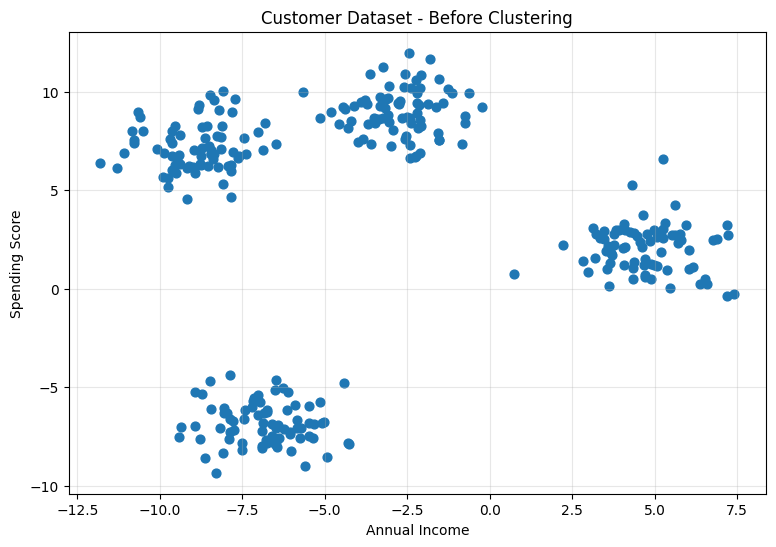

In [2]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    s=40
)

plt.title("Customer Dataset - Before Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.grid(alpha=0.3)

plt.show()

In [3]:
from sklearn.cluster import KMeans

# Create K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train model and predict clusters
df["Cluster"] = kmeans.fit_predict(X)

print("K-Means Clustering Completed!")

print("\nFirst 10 Records:")
print(df.head(10))

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

K-Means Clustering Completed!

First 10 Records:
   Annual_Income  Spending_Score  Cluster
0      -9.389561        6.303710        3
1      -9.870824        6.862056        3
2      -1.522144        7.549274        0
3      -7.140845       -5.561577        1
4     -11.284077        6.113819        3
5      -5.850436       -7.072036        1
6       4.847696        2.435551        2
7      -6.384109       -7.556579        1
8      -3.084207        8.791495        0
9       3.210315        2.761034        2

Cluster Distribution:
Cluster
0    76
1    75
2    75
3    74
Name: count, dtype: int64


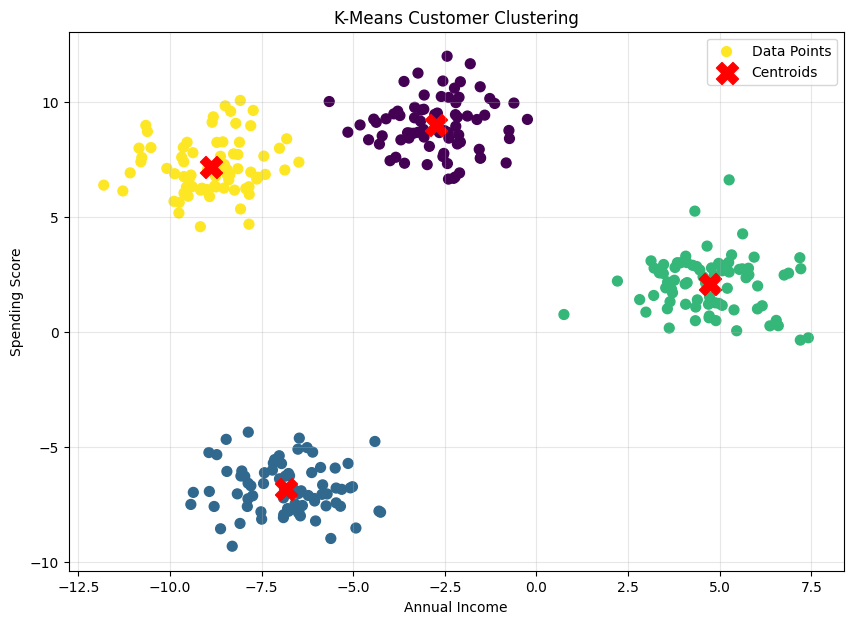

In [4]:
# Get cluster centroids
centroids = kmeans.cluster_centers_

plt.figure(figsize=(10, 7))

# Plot clustered data
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap="viridis",
    s=50,
    label="Data Points"
)

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    color="red",
    marker="X",
    s=250,
    label="Centroids"
)

plt.title("K-Means Customer Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

K Value | Inertia
------------------
      1 | 20172.95
      2 | 9666.83
      3 | 2346.88
      4 | 805.48
      5 | 729.97
      6 | 656.62
      7 | 585.09
      8 | 514.35
      9 | 461.21
     10 | 411.74


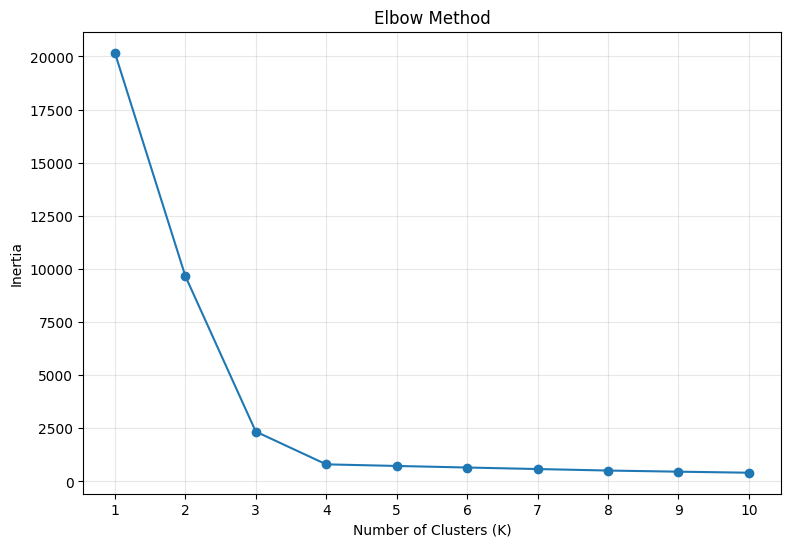

In [5]:
from sklearn.cluster import KMeans

inertia_values = []

# Test different K values
for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia_values.append(model.inertia_)

# Display inertia values
print("K Value | Inertia")
print("------------------")

for k, inertia in enumerate(inertia_values, start=1):
    print(f"{k:7} | {inertia:.2f}")

# Plot Elbow Curve
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)

plt.show()

K = 2, Silhouette Score = 0.5772
K = 3, Silhouette Score = 0.7352
K = 4, Silhouette Score = 0.7518
K = 5, Silhouette Score = 0.6327
K = 6, Silhouette Score = 0.5080
K = 7, Silhouette Score = 0.4122
K = 8, Silhouette Score = 0.3406
K = 9, Silhouette Score = 0.3460
K = 10, Silhouette Score = 0.3649


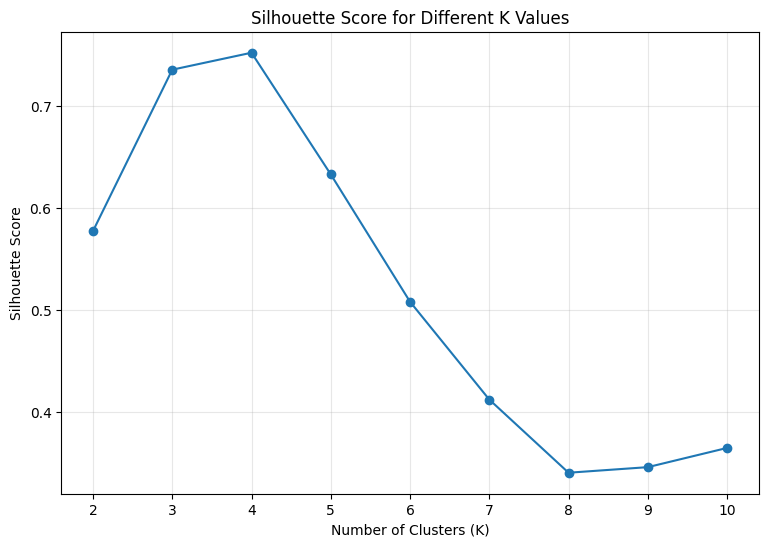

In [6]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

# Calculate silhouette score for K = 2 to 10
for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(9, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.show()

In [7]:
print("Centroid Coordinates:\n")

for i, centroid in enumerate(kmeans.cluster_centers_):
    print(f"Cluster {i}:")
    print(f"Annual Income: {centroid[0]:.2f}")
    print(f"Spending Score: {centroid[1]:.2f}")
    print("-" * 30)

Centroid Coordinates:

Cluster 0:
Annual Income: -2.73
Spending Score: 8.97
------------------------------
Cluster 1:
Annual Income: -6.82
Spending Score: -6.82
------------------------------
Cluster 2:
Annual Income: 4.73
Spending Score: 2.06
------------------------------
Cluster 3:
Annual Income: -8.88
Spending Score: 7.14
------------------------------


In [8]:
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("Annual_Income", "count"),
    Average_Income=("Annual_Income", "mean"),
    Average_Spending=("Spending_Score", "mean")
)

print("Cluster Summary:\n")
print(cluster_summary.round(2))

Cluster Summary:

         Customer_Count  Average_Income  Average_Spending
Cluster                                                  
0                    76           -2.73              8.97
1                    75           -6.82             -6.82
2                    75            4.73              2.06
3                    74           -8.88              7.14
